# Decision Trees Exercises

![DecisionTree.png](../asets/DecisionTree.png)


# Цели обучения

- Распознайте деревья решений и как их использовать для проблем классификации
- Узнайте, как определить наилучшее разделение и факторы для разделения
- Объясните сильные и слабые стороны деревьев для принятия решений
- Объясните, как деревья регрессии помогают классифицировать непрерывные значения
- Примените расширение Intel® для Scikit-learn*, чтобы использовать базовые вычислительные возможности оборудования




## Введение

Мы будем использовать набор данных качества вина для этих упражнений. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (3-9, где самый высокий - лучше) и цвет (красный или белый). Имя файла - «Wine_Quality_Data.csv».

In [1]:
from __future__ import print_function
import os
import subprocess
# в папке курса данные лежат в data/, у меня - в общей папке "Seturi de date"
data_path = ['data'] if os.path.isdir('data') else ['..', 'Seturi de date']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

from sklearnex import patch_sklearn
patch_sklearn()

%matplotlib inline
sns.set_style('whitegrid')

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные и изучите функции.
* Мы будем использовать их все для прогнозирования `color` (белого или красного), но функция цветов должна быть закодирована на целое число.

In [2]:
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath, sep=',')
print(data.shape)
print(data.dtypes.value_counts().to_dict())
data.head()

(6497, 13)
{dtype('float64'): 11, dtype('int64'): 1, <StringDtype(storage='python', na_value=nan)>: 1}


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
data.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile_acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric_acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual_sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free_sulfur_dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total_sulfur_dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


Преобразуйте цветовую функцию в целое число. Это быстрый способ сделать это с помощью  Pandas.

In [4]:
# сравнение со строкой дает True/False, перевожу в 0/1
data['color'] = (data['color'] == 'red').astype(int)
print(data['color'].value_counts().to_dict())
data.color.dtype

{0: 4898, 1: 1599}


dtype('int64')

**Ответ.**

6497 вин и 13 столбцов: 11 химических признаков (`float64`), `quality` (`int64`, от 3 до 9) и `color` (строка). Пропусков нет. Признаки в очень разных единицах, но для дерева масштабирование не нужно, разбиение по порогу от масштаба не зависит.

`color` закодирован так: white = 0 (4898 вин), red = 1 (1599 вин).

## Вопрос 2

* Используйте `StratifiedShuffleSplit` для разделения данных на наборы поездов и тестов, которые стратифицированы по качеству вина. Если возможно, сохраните индексы доли для вопроса 5 ниже.
* Проверьте процентный состав каждого уровня качества для наборов данных о поезде и тестовых данных.

In [5]:
# All data columns except for color
feature_cols = [x for x in data.columns if x != 'color']

# Split the data into two parts with 1000 points in the test data
# This creates a generator
strat_shuff_split = StratifiedShuffleSplit(n_splits=1, test_size=1000, random_state=42)

# Get the index values from the generator (сохраняю для вопроса 5)
train_idx, test_idx = next(strat_shuff_split.split(data[feature_cols], data['quality']))

# Create the data sets
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'color']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'color']
print('train:', X_train.shape, ' test:', X_test.shape)

train: (5497, 12)  test: (1000, 12)


Теперь проверьте процентную долю каждого уровня качества в обучающем и тестовом наборах данных. Как видно ниже, набор данных в основном состоит из белого вина.

In [6]:
quality_share = pd.DataFrame({'train': data.loc[train_idx, 'quality'].value_counts(normalize=True),
                              'test': data.loc[test_idx, 'quality'].value_counts(normalize=True),
                              'вин всего': data['quality'].value_counts()}).sort_index()
print(quality_share.round(4))
print()
print('доля красного вина: train', round(y_train.mean(), 4), ' test', round(y_test.mean(), 4))

          train   test  вин всего
quality                          
3        0.0045  0.005         30
4        0.0333  0.033        216
5        0.3291  0.329       2138
6        0.4366  0.436       2836
7        0.1661  0.166       1079
8        0.0297  0.030        193
9        0.0007  0.001          5

доля красного вина: train 0.2467  test 0.243


**Ответ.**

После `StratifiedShuffleSplit` по `quality` в train 5497 вин, в test 1000. Доли каждого уровня качества в train и test почти одинаковые, например у качества 6 это 0.437 и 0.436. Это важно, потому что качества 3 и 9 встречаются очень редко (30 и 5 вин), и при обычном случайном разбиении их доли могли бы сильно отличаться. Доля красного вина тоже почти одинаковая, около 24-25% в обоих наборах, то есть в основном это белое вино.

## Вопрос 3

* Постройте классификатор на основе дерева решений без ограничений на максимальную глубину, количество признаков или количество листьев.
* Определите, сколько узлов присутствует в этом (очень большом) дереве и какова его глубина.
* Используя это дерево, оцените погрешность прогнозирования на обучающем и тестовом наборах данных. Как вы думаете, что здесь происходит, исходя из различий в погрешности прогнозирования?

In [7]:
dt = DecisionTreeClassifier(random_state=42)
dt = dt.fit(X_train, y_train)

Количество узлов и максимальная фактическая глубина.

In [8]:
dt.tree_.node_count, dt.tree_.max_depth

(165, 21)

In [9]:
def measure_error(y_true, y_pred, label):
    return pd.Series({'accuracy':accuracy_score(y_true, y_pred),
                      'precision': precision_score(y_true, y_pred),
                      'recall': recall_score(y_true, y_pred),
                      'f1': f1_score(y_true, y_pred),
                      'ошибок': int((y_true != y_pred).sum())},
                      name=label)


# The error on the training and test data sets
y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

train_test_full_error = pd.concat([measure_error(y_train, y_train_pred, 'train'),
                                   measure_error(y_test, y_test_pred, 'test')],
                                  axis=1)

train_test_full_error.round(4)

,train,test
accuracy,0.9996,0.9770
precision,0.9993,0.9297
recall,0.9993,0.9794
f1,0.9993,0.9539
ошибок,2.0000,23.0000


In [10]:
print('листьев:', dt.get_n_leaves())
print('первое разбиение:', feature_cols[dt.tree_.feature[0]], '<=', round(dt.tree_.threshold[0], 2))

листьев: 83
первое разбиение: total_sulfur_dioxide <= 70.5


Дерево решений демонстрирует чуть более точные прогнозы на обучающих данных, чем на тестовых, что свидетельствует о (незначительной) переобученности. Также обратите внимание на идеальный показатель воспроизводимости для обучающих данных. Во многих случаях разница в точности прогнозов бывает даже больше, чем показано здесь.

**Ответ.**

Дерево без ограничений получилось с 165 узлами и глубиной 21 (83 листа). Первое разбиение по `total_sulfur_dioxide`, это тот же признак, который больше всего коррелировал с цветом в лабе 7.

На train всего 2 ошибки из 5497 (accuracy 0.9996), на test 23 ошибки из 1000 (0.977). По accuracy разница кажется небольшой, но ошибок на test в разы больше. Это переобучение: дерево росло, пока все листья не стали чистыми, и по сути запомнило обучающие вина. Сильнее всего на test упал precision (0.93), то есть модель иногда называет белые вина красными.

## Вопрос 4

* С помощью сетчатого поиска с перекрестной валидацией найдите дерево решений, которое демонстрирует хорошие результаты на тестовом наборе данных. Присвойте этой модели дерева решений другое имя переменной, чем в вопросе 3, чтобы обе модели можно было использовать в вопросе 6.
* Определите количество узлов и глубину этого дерева.
* Рассчитайте погрешности на обучающем и тестовом наборах данных, как и ранее, и сравните их с погрешностями дерева из вопроса 3.

In [11]:
param_grid = {'max_depth':range(1, dt.tree_.max_depth+1, 2),
              'max_features': range(1, len(dt.feature_importances_)+1)}

GR = GridSearchCV(DecisionTreeClassifier(random_state=42),
                  param_grid=param_grid,
                  scoring='accuracy',
                  cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                  n_jobs=-1)

GR = GR.fit(X_train, y_train)
print('комбинаций:', len(GR.cv_results_['params']), ' лучшие параметры:', GR.best_params_,
      f' accuracy CV: {GR.best_score_:.4f}')

комбинаций: 132  лучшие параметры: {'max_depth': 13, 'max_features': 12}  accuracy CV: 0.9869


Количество узлов и максимальная глубина дерева.

In [12]:
GR.best_estimator_.tree_.node_count, GR.best_estimator_.tree_.max_depth

(127, 13)

In [13]:
y_train_pred_gr = GR.predict(X_train)
y_test_pred_gr = GR.predict(X_test)

train_test_gr_error = pd.concat([measure_error(y_train, y_train_pred_gr, 'train'),
                                 measure_error(y_test, y_test_pred_gr, 'test')],
                                axis=1)
pd.concat({'вопрос 3': train_test_full_error, 'вопрос 4': train_test_gr_error}, axis=1).round(4)

вопрос 3          вопрос 4         
             train     test    train     test
accuracy    0.9996   0.9770   0.9982   0.9780
precision   0.9993   0.9297   0.9985   0.9368
recall      0.9993   0.9794   0.9941   0.9753
f1          0.9993   0.9539   0.9963   0.9556
ошибок      2.0000  23.0000  10.0000  22.0000

Эти ошибки тестирования немного лучше, чем предыдущие. Таким образом, можно сделать вывод, что в предыдущем примере имело место переобучение, но лишь в незначительной степени.

**Ответ.**

Перебирались `max_depth` от 1 до 21 (через 2) и `max_features` от 1 до 12, всего 132 комбинации. Лучшие параметры: `max_depth = 13`, `max_features = 12`, accuracy на кросс-валидации 0.987. Дерево стало меньше: 127 узлов и глубина 13.

На test 22 ошибки вместо 23 (accuracy 0.978 против 0.977), так что улучшение совсем маленькое. На train ошибок стало 10 вместо 2, дерево уже не так сильно запоминает данные. Значит, переобучение у первого дерева было, но небольшое.

## Вопрос 5

* Снова разделите данные на части `X` и `y`, на этот раз с `residual_sugar` в качестве прогнозируемых (`y`) данных. *Примечание:* если индексы были сохранены из результатов `StratifiedShuffleSplit` в вопросе 2, их можно использовать повторно для разделения данных.
* Используя поиск по сетке с перекрестной валидацией, найдите модель **регрессии** на основе дерева решений, которая хорошо работает на тестовом наборе данных.
* Оцените погрешности на обучающем и тестовом наборах данных с помощью среднеквадратичной ошибки.
* Постройте график, на котором будут отображены фактические *и* прогнозируемые значения остаточного сахара.

In [14]:
feature_cols = [x for x in data.columns if x != 'residual_sugar']

# Create the data sets (индексы из вопроса 2)
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'residual_sugar']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'residual_sugar']
print(y_train.describe().round(2).to_dict())

{'count': 5497.0, 'mean': 5.46, 'std': 4.77, 'min': 0.6, '25%': 1.8, '50%': 3.0, '75%': 8.1, 'max': 65.8}


In [15]:
dr = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)

param_grid = {'max_depth':range(1, dr.tree_.max_depth+1, 2),
              'max_features': range(1, len(dr.feature_importances_)+1)}

GR_sugar = GridSearchCV(DecisionTreeRegressor(random_state=42),
                        param_grid=param_grid,
                        scoring='neg_mean_squared_error',
                        cv=KFold(n_splits=5, shuffle=True, random_state=42),
                        n_jobs=-1)

GR_sugar = GR_sugar.fit(X_train, y_train)
print('глубина полного дерева:', dr.tree_.max_depth, ' комбинаций:', len(GR_sugar.cv_results_['params']))
print('лучшие параметры:', GR_sugar.best_params_, f' MSE на кросс-валидации: {-GR_sugar.best_score_:.3f}')

глубина полного дерева: 26  комбинаций: 156
лучшие параметры: {'max_depth': 21, 'max_features': 10}  MSE на кросс-валидации: 2.980


Количество узлов и максимальная глубина дерева. В этом дереве много узлов, что неудивительно, учитывая непрерывный характер данных.

In [16]:
GR_sugar.best_estimator_.tree_.node_count, GR_sugar.best_estimator_.tree_.max_depth

(7611, 21)

Ошибка на обучающем и тестовом наборах данных. Поскольку речь идет о непрерывных величинах, мы будем использовать среднеквадратичную ошибку.

In [17]:
y_train_pred_gr_sugar = GR_sugar.predict(X_train)
y_test_pred_gr_sugar  = GR_sugar.predict(X_test)

train_test_gr_sugar_error = pd.DataFrame({
    'MSE': [mean_squared_error(y_train, y_train_pred_gr_sugar), mean_squared_error(y_test, y_test_pred_gr_sugar)],
    'R2': [r2_score(y_train, y_train_pred_gr_sugar), r2_score(y_test, y_test_pred_gr_sugar)]},
    index=['train', 'test'])
train_test_gr_sugar_error.round(3)

,MSE,R2
train,0.003,1.000
test,2.767,0.873


In [18]:
# какие признаки важнее всего для сахара
imp = pd.Series(GR_sugar.best_estimator_.feature_importances_, index=feature_cols).sort_values(ascending=False)
imp.head(5).round(3)

density             0.405
color               0.391
alcohol             0.053
fixed_acidity       0.033
volatile_acidity    0.031
dtype: float64

График, отражающий соотношение фактического и прогнозируемого остаточного содержания сахара.

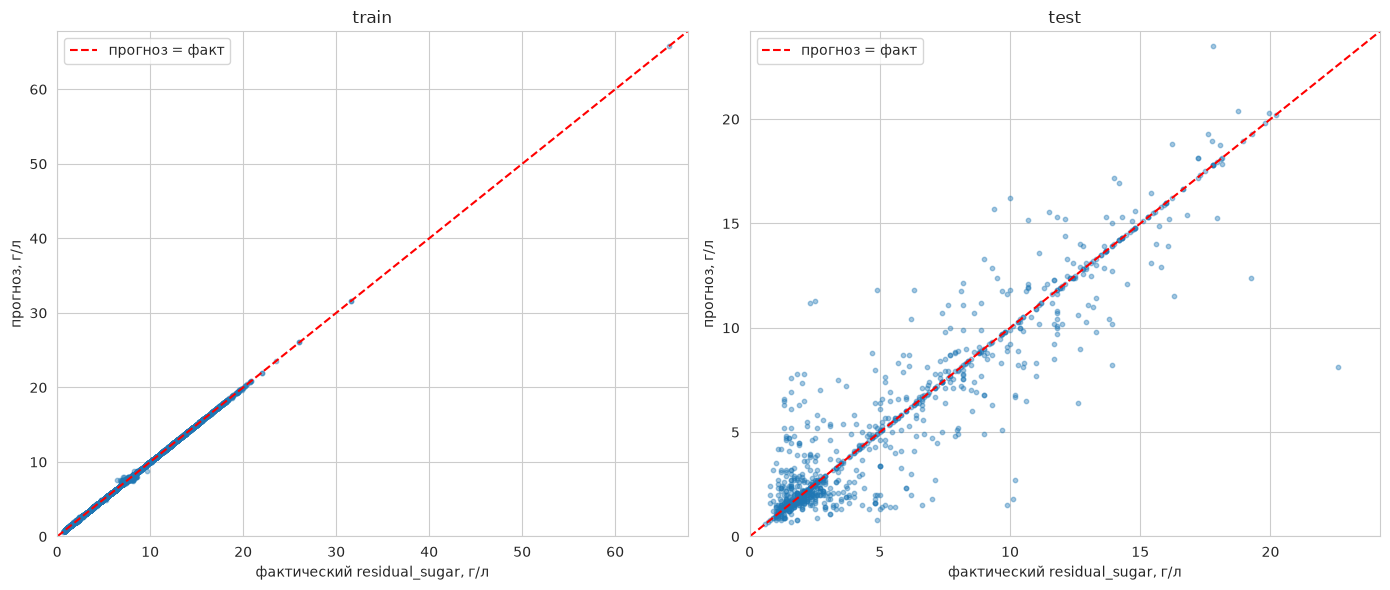

разных значений прогноза на test: 234


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, y_true, y_pred) in zip(axes, [('train', y_train, y_train_pred_gr_sugar),
                                            ('test', y_test, y_test_pred_gr_sugar)]):
    ax.scatter(y_true, y_pred, s=10, alpha=0.4)
    lim = [0, max(y_true.max(), y_pred.max()) * 1.03]
    ax.plot(lim, lim, 'r--', label='прогноз = факт')
    ax.set(xlim=lim, ylim=lim, xlabel='фактический residual_sugar, г/л', ylabel='прогноз, г/л', title=name)
    ax.legend()
plt.tight_layout()
plt.show()
print('разных значений прогноза на test:', len(np.unique(y_test_pred_gr_sugar)))

**Ответ.**

Теперь предсказываем `residual_sugar` (в среднем около 5.5 г/л). Лучшие параметры: `max_depth = 21`, `max_features = 10`. Дерево очень большое, 7611 узлов. Это потому, что цель непрерывная и почти у каждого значения сахара может быть свой лист.

MSE на train 0.003, на test 2.77 (R2 = 0.87). На train ошибка почти нулевая, то есть дерево снова переобучено, но на test все равно объясняет большую часть разброса.

Самые важные признаки - `density` (0.41) и `color` (0.39). Это логично: сахар увеличивает плотность вина, а белые вина в среднем слаще красных. На графике видно, что прогноз ступенчатый, на test всего 234 разных значения, потому что дерево выдает одно значение на лист.

## Вопрос 6 *(Необязательный)*

Этот вопрос является необязательным, так как для его решения требуется дополнительная программа командной строки (GraphViz) и библиотека Python (PyDotPlus). GraphViz можно установить с помощью менеджера пакетов в Linux и Mac. Для установки библиотеки PyDotPlus можно использовать либо `pip`, либо `conda` (`conda install -c conda-forge pydotplus`).

После установки этих программ:

* Создайте визуализацию дерева решений из вопроса 3, в котором предсказывался цвет вина, а количество признаков и/или разбиений не ограничено.
* Создайте визуализацию дерева решений из вопроса 4, в котором предсказывался цвет вина, но для нахождения оптимальной глубины и количества признаков использовался поиск по сетке.

Дерево решений из вопроса 5, скорее всего, будет иметь слишком много узлов для визуализации.

In [20]:
try:
    import pydotplus
    pydotplus_installed = True
    
except:
    print('PyDotPlus must be installed to execute the remainder of the cells associated with this question.')
    print('Please see the instructions for this question for details.')
    pydotplus_installed = False

PyDotPlus must be installed to execute the remainder of the cells associated with this question.
Please see the instructions for this question for details.


In [21]:
color_features = [c for c in data.columns if c != 'color']


# pydotplus у меня не установлен, но программа dot из graphviz есть, поэтому вызываю ее напрямую
def draw_tree(tree, size='16,9'):
    dot_data = StringIO()
    export_graphviz(tree, out_file=dot_data, filled=True, rounded=True, impurity=False,
                    feature_names=color_features, class_names=['white', 'red'])
    source = dot_data.getvalue().replace('digraph Tree {', 'digraph Tree {\nsize="' + size + '";\nratio=compress;', 1)
    if pydotplus_installed:
        png = pydotplus.graph_from_dot_data(source).create_png()
    else:
        png = subprocess.run(['dot', '-Tpng'], input=source.encode(), capture_output=True).stdout
    return Image(data=png)

Дерево из вопроса 3.

узлов: 165  глубина: 21


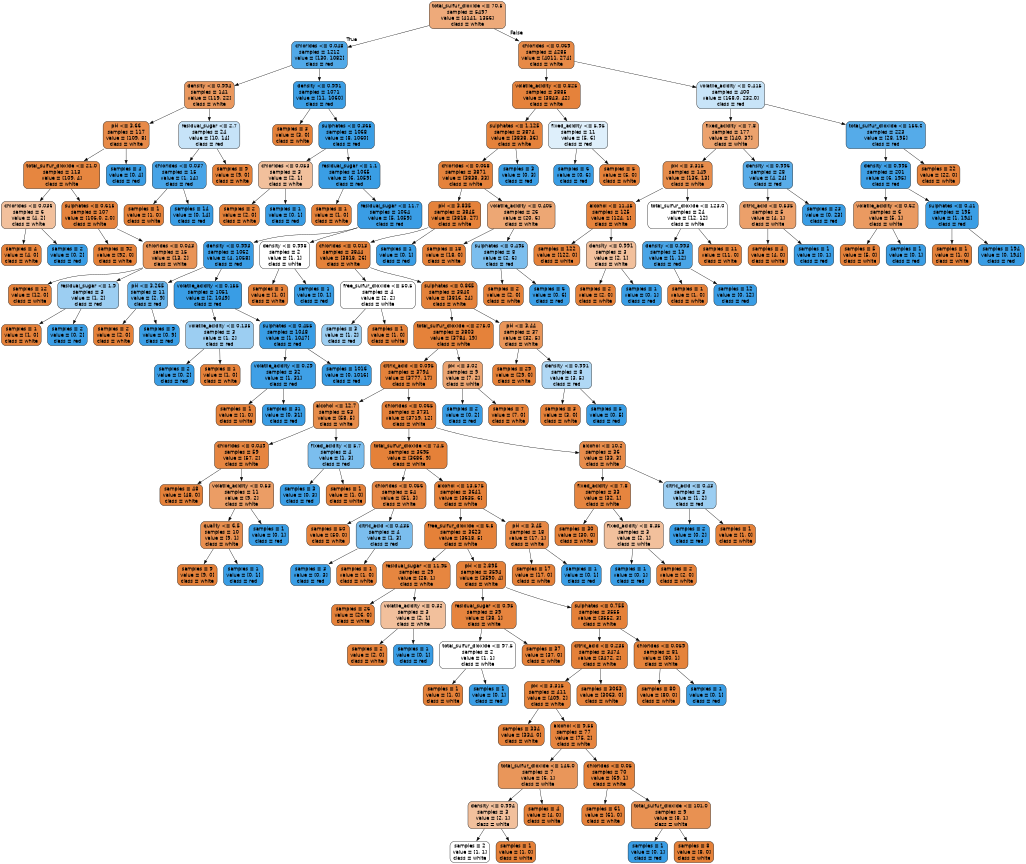

In [22]:
# дерево большое, целиком его не прочитать, но форму видно
print('узлов:', dt.tree_.node_count, ' глубина:', dt.tree_.max_depth)
draw_tree(dt)

Дерево, построенное с помощью перекрестной валидации из вопроса 4. Это дерево намного менее глубокое, чем предыдущее.

узлов: 127  глубина: 13


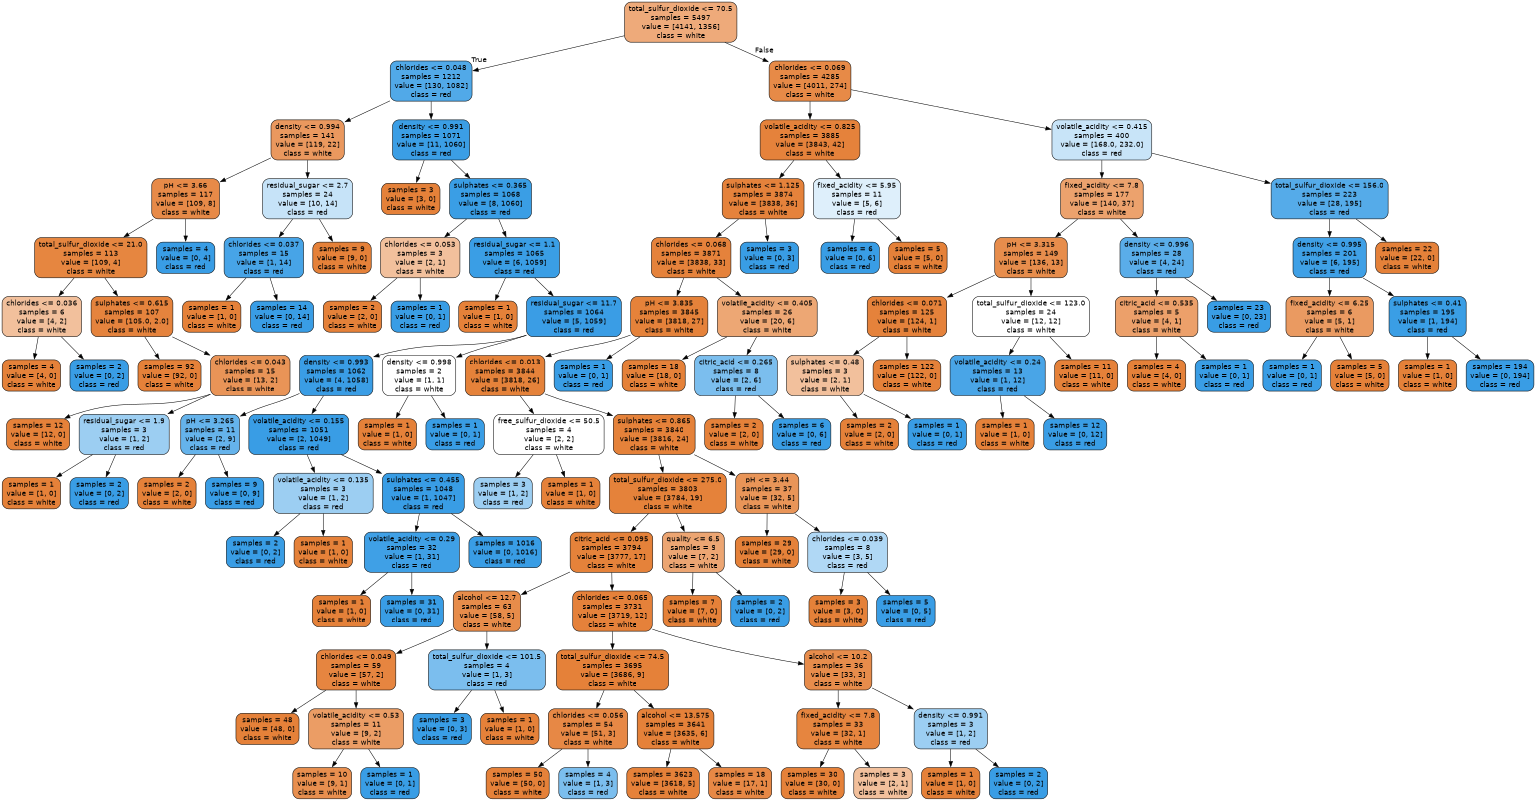

In [23]:
print('узлов:', GR.best_estimator_.tree_.node_count, ' глубина:', GR.best_estimator_.tree_.max_depth)
draw_tree(GR.best_estimator_)

**Ответ.**

pydotplus не установлен, поэтому картинка строится через программу `dot` из GraphViz напрямую.

Первое дерево (165 узлов, глубина 21) пришлось сильно уменьшить, подписи на нем не прочитать, но видно, что оно очень глубокое и внизу много маленьких листьев с одним-двумя винами.

Второе дерево (127 узлов, глубина 13) читается лучше. В корне `total_sulfur_dioxide <= 70.5`: слева почти все красные вина, справа почти все белые. Дальше большая часть вин попадает в несколько больших чистых листьев, а остальные разбиения отделяют небольшие группы нетипичных вин.

Дерево из вопроса 5 рисовать нет смысла, у него 7611 узлов.